In [1]:
%pip install -q langchain-text-splitters pypdf openai tiktoken sentence-transformers matplotlib pandas python-dotenv

Note: you may need to restart the kernel to use updated packages.


In [1]:
import os, re, json, statistics
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from pypdf import PdfReader

from langchain_text_splitters import (
    CharacterTextSplitter,
    RecursiveCharacterTextSplitter,
    TokenTextSplitter,
)

print("Imports OK")
print("Working folder:", Path.cwd())

Imports OK
Working folder: /Users/sandraobregon/Desktop/Weekthree/day2/lab-slice-docs-Google


In [2]:
load_dotenv(Path.cwd() / ".env")

print("OpenAI key found:", bool(os.getenv("OPENAI_API_KEY")))

AUDIO_PATH = Path("The_Blueprint_For_Trustworthy_AI.m4a")
print("Audio found:", AUDIO_PATH.exists())

pdf_files = list(Path.cwd().glob("*.pdf"))
print("PDF files:", [path.name for path in pdf_files])

OpenAI key found: True
Audio found: True
PDF files: ['ai_hleg_ethics_guidelines_for_trustworthy_ai-en_87F84A41-A6E8-F38C-BFF661481B40077B_60419.pdf']


In [3]:
PDF_PATH = Path(
    "ai_hleg_ethics_guidelines_for_trustworthy_ai-en_"
    "87F84A41-A6E8-F38C-BFF661481B40077B_60419.pdf"
)

reader = PdfReader(PDF_PATH)
pdf_pages = [page.extract_text() or "" for page in reader.pages]
pdf_text = "\n".join(pdf_pages)

print("PDF pages:", len(pdf_pages))
print("PDF characters:", len(pdf_text))
print("First 200 characters:")
print(pdf_text[:200])

PDF pages: 41
PDF characters: 156411
First 200 characters:
 
 
 
 
 
 
INDEPENDENT 
HIGH-LEVEL EXPERT GROUP ON 
ARTIFICIAL INTELLIGENCE 
SET UP BY THE EUROPEAN COMMISSION 
 
 
 
 
 
 
ETHICS GUIDELINES 
FOR TRUSTWORTHY AI 
 
 
 
 
 
 
ETHICS GUIDELINES FOR TR


In [4]:
print("First 200 characters, including whitespace:")
print(repr(pdf_text[:200]))

for page_number, text in enumerate(pdf_pages, start=1):
    if text.strip():
        print("First page with text:", page_number)
        print(text.strip()[:300])
        break

First 200 characters, including whitespace:
' \n \n \n \n \n \nINDEPENDENT \nHIGH-LEVEL EXPERT GROUP ON \nARTIFICIAL INTELLIGENCE \nSET UP BY THE EUROPEAN COMMISSION \n \n \n \n \n \n \nETHICS GUIDELINES \nFOR TRUSTWORTHY AI \n \n \n \n \n \n \nETHICS GUIDELINES FOR TR'
First page with text: 1
INDEPENDENT 
HIGH-LEVEL EXPERT GROUP ON 
ARTIFICIAL INTELLIGENCE 
SET UP BY THE EUROPEAN COMMISSION 
 
 
 
 
 
 
ETHICS GUIDELINES 
FOR TRUSTWORTHY AI


In [5]:
import subprocess

TRANSCRIPT_PATH = Path("transcript.txt")
PIECES_DIR = Path("_pieces")
PIECES_DIR.mkdir(exist_ok=True)

print("Transcript already exists:", TRANSCRIPT_PATH.exists())
print("Audio size MB:", round(AUDIO_PATH.stat().st_size / 1_000_000, 2))

subprocess.run(
    [
        "ffmpeg", "-v", "error", "-y",
        "-i", str(AUDIO_PATH),
        "-ac", "1",
        "-b:a", "64k",
        "-f", "segment",
        "-segment_time", "600",
        "-reset_timestamps", "1",
        str(PIECES_DIR / "piece_%02d.mp3"),
    ],
    check=True,
)

audio_pieces = sorted(PIECES_DIR.glob("piece_*.mp3"))

for piece in audio_pieces:
    print(piece.name, round(piece.stat().st_size / 1_000_000, 2), "MB")

Transcript already exists: False
Audio size MB: 30.17
piece_00.mp3 4.8 MB
piece_01.mp3 2.7 MB


In [6]:
from openai import OpenAI

client = OpenAI()

if TRANSCRIPT_PATH.exists() and TRANSCRIPT_PATH.stat().st_size > 0:
    podcast_text = TRANSCRIPT_PATH.read_text(encoding="utf-8")
    print("Saved transcript loaded.")
else:
    texts = []

    for piece in audio_pieces:
        saved_piece = piece.with_suffix(".txt")

        if saved_piece.exists() and saved_piece.stat().st_size > 0:
            text = saved_piece.read_text(encoding="utf-8")
            print(piece.name, "loaded from saved transcript")
        else:
            with piece.open("rb") as audio_file:
                response = client.audio.transcriptions.create(
                    model="whisper-1",
                    file=audio_file,
                )

            text = response.text
            saved_piece.write_text(text, encoding="utf-8")
            print(piece.name, "transcribed and saved")

        texts.append(text)

    podcast_text = "\n\n".join(texts)
    TRANSCRIPT_PATH.write_text(podcast_text, encoding="utf-8")

print("Transcript characters:", len(podcast_text))
print(podcast_text[:300])

piece_00.mp3 transcribed and saved
piece_01.mp3 transcribed and saved
Transcript characters: 16457
So imagine for a second you're driving across, I don't know, a massive suspension bridge. OK. You don't pull over halfway across, get out and demand to see the blueprints, right? You don't interview the welding crew. No. You just, you trust it. You just drive. You trust the bridge. You trust the eng


In [7]:
fixed_splitter = CharacterTextSplitter(
    separator="",
    chunk_size=500,
    chunk_overlap=50,
    strip_whitespace=False,
)

pdf_fixed_chunks = fixed_splitter.split_text(pdf_text)
podcast_fixed_chunks = fixed_splitter.split_text(podcast_text)

for source, chunks in [
    ("PDF", pdf_fixed_chunks),
    ("Podcast", podcast_fixed_chunks),
]:
    sizes = [len(chunk) for chunk in chunks]

    print(f"\n{source}")
    print("Chunks:", len(chunks))
    print("Average characters:", round(statistics.mean(sizes), 1))
    print("Minimum:", min(sizes))
    print("Maximum:", max(sizes))
    print("First chunk ending:", repr(chunks[0][-50:]))
    print("Second chunk beginning:", repr(chunks[1][:50]))


PDF
Chunks: 348
Average characters: 499.3
Minimum: 261
Maximum: 500
First chunk ending: 'orthy AI put forward in these Guidelines, \nalthoug'
Second chunk beginning: 'orthy AI put forward in these Guidelines, \nalthoug'

Podcast
Chunks: 37
Average characters: 493.4
Minimum: 257
Maximum: 500
First chunk ending: " Exactly. But now let's switch gears. Think about "
Second chunk beginning: " Exactly. But now let's switch gears. Think about "


In [8]:
fixed_results = []
fixed_experiments = {}

for source, text in [("PDF", pdf_text), ("Podcast", podcast_text)]:
    for size in [500, 1000, 2000]:
        for overlap in [0, 50, 100]:
            splitter = CharacterTextSplitter(
                separator="",
                chunk_size=size,
                chunk_overlap=overlap,
                strip_whitespace=False,
            )
            chunks = splitter.split_text(text)
            lengths = [len(chunk) for chunk in chunks]

            fixed_experiments[(source, size, overlap)] = chunks
            fixed_results.append({
                "source": source,
                "chunk_size_chars": size,
                "overlap_chars": overlap,
                "chunks": len(chunks),
                "avg_chars": round(statistics.mean(lengths), 1),
                "min_chars": min(lengths),
                "max_chars": max(lengths),
            })

fixed_df = pd.DataFrame(fixed_results)
display(fixed_df)

,source,chunk_size_chars,overlap_chars,chunks,avg_chars,min_chars,max_chars
0,PDF,500,0,313,499.7,411,500
1,PDF,500,50,348,499.3,261,500
2,PDF,500,100,391,499.8,411,500
3,PDF,1000,0,157,996.2,411,1000
4,PDF,1000,50,165,997.6,611,1000
5,PDF,1000,100,174,998.3,711,1000
6,PDF,2000,0,79,1979.9,411,2000
7,PDF,2000,50,81,1980.4,411,2000
8,PDF,2000,100,83,1983.3,611,2000
9,Podcast,500,0,33,498.7,457,500


In [9]:
def pct_clean_boundaries(chunks):
    """Measure non-empty chunks ending in sentence punctuation."""
    non_empty = [chunk.strip() for chunk in chunks if chunk.strip()]

    if not non_empty:
        return 0.0

    clean = sum(chunk[-1] in ".?!" for chunk in non_empty)
    return clean / len(non_empty) * 100


fixed_df["clean_endings_pct"] = [
    round(
        pct_clean_boundaries(
            fixed_experiments[
                (row.source, row.chunk_size_chars, row.overlap_chars)
            ]
        ),
        1,
    )
    for row in fixed_df.itertuples()
]

display(fixed_df)

,source,chunk_size_chars,overlap_chars,chunks,avg_chars,min_chars,max_chars,clean_endings_pct
0,PDF,500,0,313,499.7,411,500,2.2
1,PDF,500,50,348,499.3,261,500,3.2
2,PDF,500,100,391,499.8,411,500,3.3
3,PDF,1000,0,157,996.2,411,1000,3.2
4,PDF,1000,50,165,997.6,611,1000,3.6
5,PDF,1000,100,174,998.3,711,1000,1.7
6,PDF,2000,0,79,1979.9,411,2000,3.8
7,PDF,2000,50,81,1980.4,411,2000,6.2
8,PDF,2000,100,83,1983.3,611,2000,1.2
9,Podcast,500,0,33,498.7,457,500,9.1


In [10]:
paragraph_results = []

for source, text in [("PDF", pdf_text), ("Podcast", podcast_text)]:
    for separator in ["", "\n\n"]:
        splitter = CharacterTextSplitter(
            separator=separator,
            chunk_size=1000,
            chunk_overlap=50,
            strip_whitespace=False,
        )
        chunks = splitter.split_text(text)
        sizes = [len(chunk) for chunk in chunks]

        paragraph_results.append({
            "source": source,
            "separator": repr(separator),
            "paragraph_breaks": text.count("\n\n"),
            "chunks": len(chunks),
            "avg_chars": round(statistics.mean(sizes), 1),
            "max_chars": max(sizes),
            "over_1000_chars": sum(size > 1000 for size in sizes),
            "clean_endings_pct": round(pct_clean_boundaries(chunks), 1),
        })

display(pd.DataFrame(paragraph_results))

Created a chunk of size 28061, which is longer than the specified 1000
Created a chunk of size 29967, which is longer than the specified 1000
Created a chunk of size 23694, which is longer than the specified 1000
Created a chunk of size 10586, which is longer than the specified 1000


,source,separator,paragraph_breaks,chunks,avg_chars,max_chars,over_1000_chars,clean_endings_pct
0,PDF,'',3,165,997.6,1000,0,3.6
1,PDF,'\n\n',3,4,39101.2,74683,4,50.0
2,Podcast,'',1,18,961.5,1000,0,5.6
3,Podcast,'\n\n',1,2,8227.5,10586,2,100.0


El splitter que sí utiliza "\n\n",  no recurre a otros separadores para dividir los bloques que siguen siendo demasiado grandes.
39.101,2 y 8.227,5 son los tamaños medios de los fragmentos del PDF y del podcast.
El podcast obtuvo un 100 % de finales limpios, pero su fragmento más grande tenía 10.586 caracteres frente a los 1000 solicitados y eso es porque la métrica de finales limpios solo revisa la puntuación final; no comprueba el tamaño ni la coherencia del fragmento

In [11]:
import tiktoken

encoding = tiktoken.get_encoding("cl100k_base")

recursive_splitter = RecursiveCharacterTextSplitter.from_tiktoken_encoder(
    encoding_name="cl100k_base",
    chunk_size=1000,
    chunk_overlap=50,
    separators=["\n\n", "\n", " ", ""],
    strip_whitespace=False,
)

pdf_recursive_chunks = recursive_splitter.split_text(pdf_text)
podcast_recursive_chunks = recursive_splitter.split_text(podcast_text)

for source, chunks in [
    ("PDF", pdf_recursive_chunks),
    ("Podcast", podcast_recursive_chunks),
]:
    token_sizes = [len(encoding.encode(chunk)) for chunk in chunks]

    print(f"\n{source}")
    print("Chunks:", len(chunks))
    print("Maximum tokens:", max(token_sizes))
    print("Clean endings %:", round(pct_clean_boundaries(chunks), 1))
    print("First chunk ending:", repr(chunks[0][-100:]))


PDF
Chunks: 38
Maximum tokens: 952
Clean endings %: 28.9
First chunk ending: 'f, in practic e, tensions arise between these \ncomponents, society should endeavour to align them.  '

Podcast
Chunks: 6
Maximum tokens: 1000
Clean endings %: 40.0
First chunk ending: 'ving our self-determination. Principle two is prevention of harm. Safety first. This covers physical'


In [12]:
for source, chunks in [
    ("PDF", pdf_recursive_chunks),
    ("Podcast", podcast_recursive_chunks),
]:
    empty = [
        (index, repr(chunk))
        for index, chunk in enumerate(chunks)
        if not chunk.strip()
    ]

    print(source)
    print("Total chunks:", len(chunks))
    print("Non-empty chunks:", sum(bool(c.strip()) for c in chunks))
    print("Whitespace-only chunks:", empty)

PDF
Total chunks: 38
Non-empty chunks: 38
Whitespace-only chunks: []
Podcast
Total chunks: 6
Non-empty chunks: 5
Whitespace-only chunks: [(3, "'\\n'")]


In [13]:
pdf_recursive_chunks = [
    chunk for chunk in pdf_recursive_chunks if chunk.strip()
]
podcast_recursive_chunks = [
    chunk for chunk in podcast_recursive_chunks if chunk.strip()
]

print("PDF usable chunks:", len(pdf_recursive_chunks))
print("Podcast usable chunks:", len(podcast_recursive_chunks))

PDF usable chunks: 38
Podcast usable chunks: 5


In [14]:
separator_options = {
    "structure_first": ["\n\n", "\n", ". ", " ", ""],
    "sentence_first": [". ", "\n\n", "\n", " ", ""],
}

recursive_results = []
recursive_experiments = {}

for source, text in [("PDF", pdf_text), ("Podcast", podcast_text)]:
    for size in [500, 1000, 2000]:
        for priority, separators in separator_options.items():
            splitter = RecursiveCharacterTextSplitter.from_tiktoken_encoder(
                encoding_name="cl100k_base",
                chunk_size=size,
                chunk_overlap=50,
                separators=separators,
                keep_separator="end",
                strip_whitespace=False,
            )

            raw_chunks = splitter.split_text(text)
            chunks = [chunk for chunk in raw_chunks if chunk.strip()]
            chars = [len(chunk) for chunk in chunks]
            tokens = [len(encoding.encode(chunk)) for chunk in chunks]

            recursive_experiments[(source, size, priority)] = chunks
            recursive_results.append({
                "source": source,
                "target_tokens": size,
                "separator_priority": priority,
                "chunks": len(chunks),
                "empty_removed": len(raw_chunks) - len(chunks),
                "avg_chars": round(statistics.mean(chars), 1),
                "max_tokens": max(tokens),
                "over_token_limit": sum(n > size for n in tokens),
                "clean_endings_pct": round(
                    pct_clean_boundaries(chunks), 1
                ),
            })

recursive_df = pd.DataFrame(recursive_results)
display(recursive_df)

,source,target_tokens,separator_priority,chunks,empty_removed,avg_chars,max_tokens,over_token_limit,clean_endings_pct
0,PDF,500,structure_first,73,0,2340.0,500,0,28.8
1,PDF,500,sentence_first,77,0,2141.2,500,0,97.4
2,PDF,1000,structure_first,35,0,4648.8,999,0,31.4
3,PDF,1000,sentence_first,36,0,4477.3,977,0,100.0
4,PDF,2000,structure_first,18,0,8854.1,1990,0,22.2
5,PDF,2000,sentence_first,17,0,9331.5,1990,0,100.0
6,Podcast,500,structure_first,9,1,1967.2,460,0,100.0
7,Podcast,500,sentence_first,9,0,2000.0,457,0,100.0
8,Podcast,1000,structure_first,5,1,3396.4,916,0,100.0
9,Podcast,1000,sentence_first,4,0,4233.8,920,0,100.0


In [15]:
for source in ["PDF", "Podcast"]:
    for priority in separator_options:
        chunks = recursive_experiments[(source, 1000, priority)]

        print(f"\n--- {source} | {priority} ---")
        print("Chunk 1 ending:", repr(chunks[0][-200:]))
        print("Chunk 2 beginning:", repr(chunks[1][:200]))


--- PDF | structure_first ---
Chunk 1 ending: ' ethical and robust AI. Addressed to all stakeholders, these Guidelines seek to go \nbeyond a list of ethical principles, by providing guidance on how such principles can be operationalised in socio -\n'
Chunk 2 beginning: 'components: fostering and securing ethical and robust AI. Addressed to all stakeholders, these Guidelines seek to go \nbeyond a list of ethical principles, by providing guidance on how such principles '

--- PDF | sentence_first ---
Chunk 1 ending: ' AI. Addressed to all stakeholders, these Guidelines seek to go \nbeyond a list of ethical principles, by providing guidance on how such principles can be operationalised in socio -\ntechnical systems. '
Chunk 2 beginning: 'Addressed to all stakeholders, these Guidelines seek to go \nbeyond a list of ethical principles, by providing guidance on how such principles can be operationalised in socio -\ntechnical systems. Guida'

--- Podcast | structure_first ---
Chunk 1 ending:

El contraste que se obtuvo fue bueno por el punto pasando de 31,4% al 100% corresponde al PDF con tamaño objetivo de 1000 tokens, al priorizar ". " y conservarlo al final, en el ejemplo: la primera variante cortó en socio -, mientras que la segunda conservó hasta technical systems.
se respetan el límite de tokens pero el 100 % no demuestra por sí solo coherencia ni respeto de títulos de sección. En el podcast ambas variantes coinciden en el corte inspeccionado pero terminar en punto no garantiza contexto suficiente ni conservar los cambios de hablante.

In [16]:
token_results = []
token_experiments = {}

for source, text in [("PDF", pdf_text), ("Podcast", podcast_text)]:
    for size in [500, 1000]:
        splitter = TokenTextSplitter(
            encoding_name="cl100k_base",
            chunk_size=size,
            chunk_overlap=50,
        )

        raw_chunks = splitter.split_text(text)
        chunks = [chunk for chunk in raw_chunks if chunk.strip()]
        chars = [len(chunk) for chunk in chunks]
        tokens = [len(encoding.encode(chunk)) for chunk in chunks]

        token_experiments[(source, size)] = chunks
        token_results.append({
            "source": source,
            "target_tokens": size,
            "chunks": len(chunks),
            "avg_chars": round(statistics.mean(chars), 1),
            "min_chars": min(chars),
            "max_chars": max(chars),
            "max_tokens": max(tokens),
            "clean_endings_pct": round(
                pct_clean_boundaries(chunks), 1
            ),
        })

token_df = pd.DataFrame(token_results)
display(token_df)

,source,target_tokens,chunks,avg_chars,min_chars,max_chars,max_tokens,clean_endings_pct
0,PDF,500,71,2443.3,748,2776,500,1.4
1,PDF,1000,34,4836.4,1218,5326,1000,8.8
2,Podcast,500,8,2267.0,1565,2500,500,25.0
3,Podcast,1000,4,4316.5,3130,4864,1000,25.0


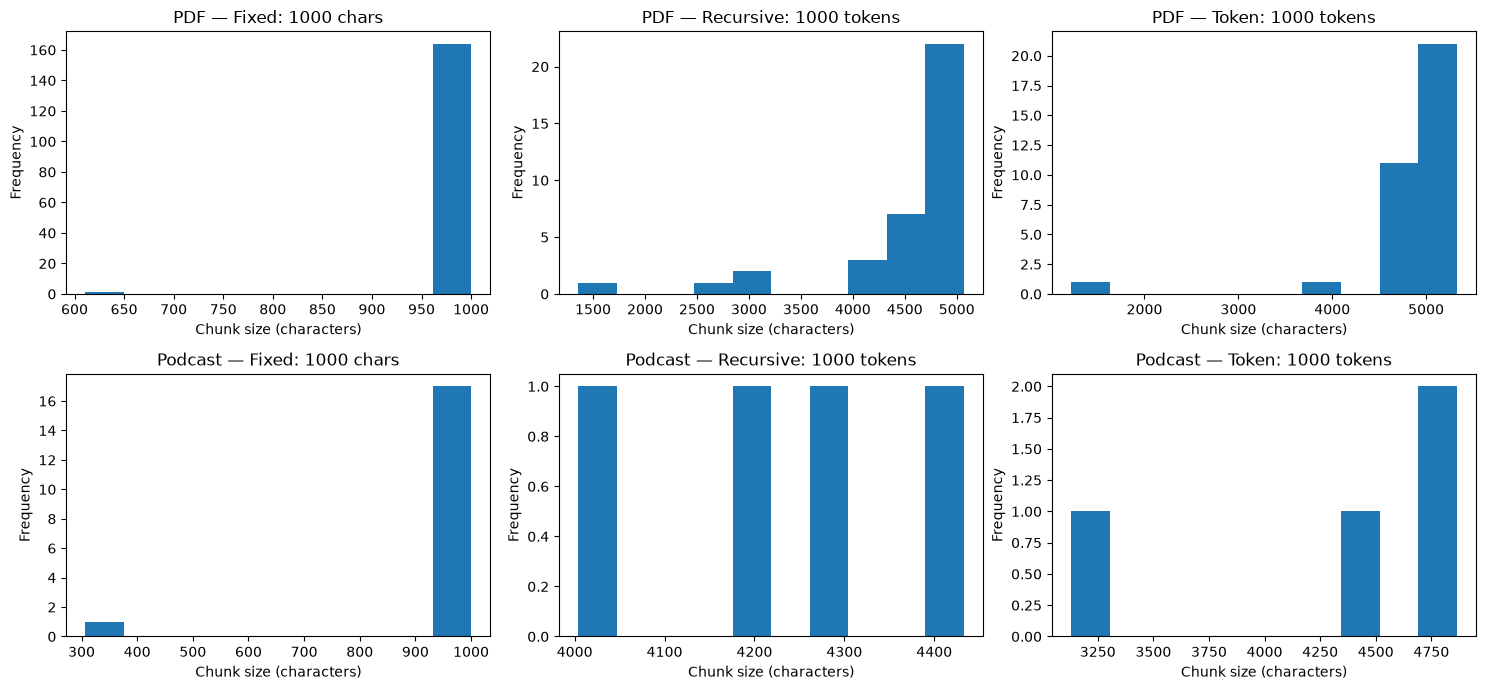

In [17]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))

for row, source in enumerate(["PDF", "Podcast"]):
    variants = [
        ("Fixed: 1000 chars",
         fixed_experiments[(source, 1000, 50)]),
        ("Recursive: 1000 tokens",
         recursive_experiments[(source, 1000, "sentence_first")]),
        ("Token: 1000 tokens",
         token_experiments[(source, 1000)]),
    ]

    for col, (label, chunks) in enumerate(variants):
        axes[row, col].hist([len(c) for c in chunks], bins=10)
        axes[row, col].set_title(f"{source} — {label}")
        axes[row, col].set_xlabel("Chunk size (characters)")
        axes[row, col].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

In [18]:
chunks = token_experiments[("Podcast", 1000)]

for index in range(min(2, len(chunks) - 1)):
    print(f"\nBoundary {index + 1}")
    print("Ending:", repr(chunks[index][-200:]))
    print("Next beginning:", repr(chunks[index + 1][:200]))


Boundary 1
Ending: "ldn't deceive you into clicking something you wouldn't otherwise choose. It's about preserving our self-determination. Principle two is prevention of harm. Safety first. This covers physical integrity"
Next beginning: ".I. shouldn't hurt us or condition us or manipulate us. It shouldn't deceive you into clicking something you wouldn't otherwise choose. It's about preserving our self-determination. Principle two is p"

Boundary 2
Ending: "ance. Now we all know about things like GDPR, but the source focuses on something called inference risks. This part actually unsettled me. It should. We tend to think privacy means, okay, I won't tell"
Next beginning: ' Requirement three is privacy and data governance. Now we all know about things like GDPR, but the source focuses on something called inference risks. This part actually unsettled me. It should. We te'


Ambas fuentes: recursivo con prioridad de frases.
Configuración inicial: 1000 tokens y overlap objetivo de 50.
Evidencia: 100 % de finales con puntuación en ambos textos y mejores cortes en los ejemplos inspeccionados.
Limitación: todavía no hemos demostrado que preserve turnos ni que mejore la recuperación de respuestas.

In [19]:
query_es = (
    "¿Para que la IA sea confiable, basta con cumplir uno de los "
    "tres componentes: ser lícita, ética o robusta?"
)

query_en = (
    "For AI to be trustworthy, is it enough to meet only one "
    "of the three components: lawful, ethical, or robust?"
)

selected_pdf_chunks = recursive_experiments[
    ("PDF", 1000, "sentence_first")
]

# Search for chunks containing all three component names.
search_terms = ["lawful", "ethical", "robust"]
retrieved_evidence = []

for index, chunk in enumerate(selected_pdf_chunks):
    normalized = " ".join(chunk.lower().split())

    if all(term in normalized for term in search_terms):
        retrieved_evidence.append({
            "chunk_id": f"pdf_recursive_1000_{index}",
            "source": PDF_PATH.name,
            "text": chunk,
        })

print("Pregunta:", query_es)
print("Search question:", query_en)
print("Matching chunks:", len(retrieved_evidence))

for record in retrieved_evidence:
    print("\nCHUNK ID:", record["chunk_id"])
    print("SOURCE:", record["source"])
    print("TEXT:\n", record["text"])

Pregunta: ¿Para que la IA sea confiable, basta con cumplir uno de los tres componentes: ser lícita, ética o robusta?
Search question: For AI to be trustworthy, is it enough to meet only one of the three components: lawful, ethical, or robust?
Matching chunks: 7

CHUNK ID: pdf_recursive_1000_0
SOURCE: ai_hleg_ethics_guidelines_for_trustworthy_ai-en_87F84A41-A6E8-F38C-BFF661481B40077B_60419.pdf
TEXT:
  
 
 
 
 
 
INDEPENDENT 
HIGH-LEVEL EXPERT GROUP ON 
ARTIFICIAL INTELLIGENCE 
SET UP BY THE EUROPEAN COMMISSION 
 
 
 
 
 
 
ETHICS GUIDELINES 
FOR TRUSTWORTHY AI 
 
 
 
 
 
 
ETHICS GUIDELINES FOR TRUSTWORTHY AI 
 
High-Level Expert Group on Artificial Intelligence 
 
 
 
 
 
 
 
 
This document was written by the High-Level Expert Group on AI (AI HLEG) . The members of the AI HLEG 
named in this document support the overall framework for Trustworthy AI put forward in these Guidelines, 
although they do not necessarily agree with every single statement in the document .  
 
The Trustworthy

## Grounded answer

El grupo independiente AI HLEG, creado por la Comisión Europea, que elaboró la guía, indica que no es suficiente cumplir solo uno de los tres componentes(ser lícita, ética, robusta), idealmente, los tres componentes funcionan en armonía y se solapan en su operación. Los tres deben cumplirse durante todo el ciclo de vida.
Para que una IA sea confiable debe cumplir:
- Cada componente (ser lícita, ética y robusta) es necesario pero ninguno es suficiente por sí solo.
- Cumplir únicamente con la legalidad, la ética o la robustez de manera aislada no garantiza la confianza en la IA, ya que pueden surgir tensiones entre estos elementos y es responsabilidad de la sociedad alinear los tres.
[pdf_recursive_1000_0; pdf_recursive_1000_3]

In [20]:
EVIDENCE_DIR = Path("evidence")
EVIDENCE_DIR.mkdir(exist_ok=True)

retrieval_record = {
    "query_es": query_es,
    "query_en": query_en,
    "method": "keyword_filter_all_terms",
    "search_terms": search_terms,
    "source": PDF_PATH.name,
    "strategy": "recursive_sentence_first",
    "chunk_size_tokens": 1000,
    "target_overlap_tokens": 50,
    "encoding": "cl100k_base",
    "retrieved_chunks": retrieved_evidence,
}

(EVIDENCE_DIR / "retrieval_trace.json").write_text(
    json.dumps(retrieval_record, indent=2, ensure_ascii=False),
    encoding="utf-8",
)

print("Saved: evidence/retrieval_trace.json")
print("Retrieved chunks:", len(retrieved_evidence))

Saved: evidence/retrieval_trace.json
Retrieved chunks: 7


## Grounding risk
Encontrar las palabras lawful, ethical y robust por si solas, no afirma que cada componente es necesario pero que ninguno basta por sí solo.
Por lo cual puede producirse una no buena interpretación al usar solo coincidencias de palabras porque podría interpretarse que solo basta con una, se interpretaria como un "or" y no como un "and".
Lo evitaría revisando las frases completas del fragmento pdf_recursive_1000_0, donde se indica que los tres componentes deben cumplirse y que cada uno es necesario, pero ninguno es suficiente por sí solo.

In [21]:
comparison_rows = []

for source in ["PDF", "Podcast"]:
    variants = [
        ("Fixed", 1000, "characters", 50, "characters",
         fixed_experiments[(source, 1000, 50)]),
        ("Recursive — sentence first", 1000, "tokens", 50, "tokens",
         recursive_experiments[(source, 1000, "sentence_first")]),
        ("Token", 1000, "tokens", 50, "tokens",
         token_experiments[(source, 1000)]),
    ]

    for strategy, size, unit, overlap, overlap_unit, chunks in variants:
        lengths = [len(chunk) for chunk in chunks]

        comparison_rows.append({
            "source": source,
            "strategy": strategy,
            "target_size": size,
            "size_unit": unit,
            "target_overlap": overlap,
            "overlap_unit": overlap_unit,
            "chunks": len(chunks),
            "avg_chars": round(statistics.mean(lengths), 1),
            "min_chars": min(lengths),
            "max_chars": max(lengths),
            "clean_endings_pct": round(
                pct_clean_boundaries(chunks), 1
            ),
        })

comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df)

,source,strategy,target_size,size_unit,target_overlap,overlap_unit,chunks,avg_chars,min_chars,max_chars,clean_endings_pct
0,PDF,Fixed,1000,characters,50,characters,165,997.6,611,1000,3.6
1,PDF,Recursive — sentence first,1000,tokens,50,tokens,36,4477.3,1358,5069,100.0
2,PDF,Token,1000,tokens,50,tokens,34,4836.4,1218,5326,8.8
3,Podcast,Fixed,1000,characters,50,characters,18,961.5,307,1000,5.6
4,Podcast,Recursive — sentence first,1000,tokens,50,tokens,4,4233.8,4004,4433,100.0
5,Podcast,Token,1000,tokens,50,tokens,4,4316.5,3130,4864,25.0


## Trade-offs

| Strategy | Advantage | Limitation | When I would use it |
|---|---|---|---|
| Fixed-size | Produces predictable sizes in characters. | Can split words and sentences. | As a simple baseline when comparing chunking strategies. |
| Recursive | Tries alternative separators to preserve text boundaries. | Does not guarantee complete ideas, section boundaries, or speaker turns. | As a starting point for these PDFs and transcripts, followed by manual checks. |
| Token-based | Controls chunk size using the selected tokenizer. | Can cut sentences and leave incomplete context. | When token-window control is the main priority. |

I did not try semantic chunking because it was optional. My recommendation to use recursive chunking may change. It is based on the text breaks and punctuation I checked, not on a comparison of how well each strategy retrieves relevant information.